# **Regression Modeling and Evaluation Notebook**



---
## **Main Idea of the Project**
This part is about building a regression system that can predict a numerical value using machine learning. We start by loading prepared data, then we test different models to see which one works best. After that, we improve the best models using tuning, select the final model, analyze important features, and finally save it so it can be used later for predictions.

The goal is to understand:

*   Which model works best
*   Why it works better
*   What the data looks like (simple or complex)



---





***1. Imports***

Before starting, we need to import all the tools required for data handling, building models, evaluating performance, and saving the final model. Each library has a specific role in the machine learning pipeline.

In [1]:
# Import basic tools for data handling and math operations
import pandas as pd
import numpy as np

# Import regression models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

# Tools to split data, tune models, and validate performance
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score

# Metrics to check how good the model is
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# For plotting graphs (visual analysis)
import matplotlib.pyplot as plt
import seaborn as sns

# To save the final trained model
import joblib



---

***2. Load preprocessed data***

Here we load the dataset that was
 cleaned and prepared. We separate input features (X) and target values (y) for both training and testing so the model can learn and later be evaluated properly.

In [2]:
# Load training and testing features from Excel files
X_train = pd.read_excel("X_train_preprocessed.xlsx")
X_test = pd.read_excel("X_test_preprocessed.xlsx")

# Load what we want to predict
y_train = pd.read_excel("y_train.xlsx").values.ravel()
y_test = pd.read_excel("y_test.xlsx").values.ravel()

print("Data loaded successfully!")

Data loaded successfully!




---
***3. Sanity check***

Before training models, check if the data is correct. Verify the shape of datasets and make sure there are no missing values that could affect model performance.


In [3]:
print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

##Check missing values in the data
print("Missing values (train):", X_train.isnull().sum().sum())
print("Missing values (test):", X_test.isnull().sum().sum())

Train shape: (479, 66)
Test shape: (479, 66)
Missing values (train): 0
Missing values (test): 0




---
***4. Baseline models***

Define multiple regression models to compare their performance.

 The idea is to test simple and advanced models to see which one predicts the best before tuning.


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Creating different regression models to compare their performance
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(random_state=42),
     "Polynomial Regression": Pipeline([
        ("poly_features", PolynomialFeatures(degree=2)),
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())
    ])

    }

***5. Evaluation function***

Create a function that trains a model, makes predictions, and calculates performance metrics. This helps us avoid repeating the same code for every model.

In [5]:
# Function to train a model and evaluate its performance
def evaluate_model(name, model, X_train, X_test, y_train, y_test):

    # Training the model
    model.fit(X_train, y_train)

    # Making predictions on test data
    y_pred = model.predict(X_test)

    # Calculate errors and performance scores
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Print results
    print(f"\n{name}")
    print("-" * 30)
    print("MSE :", mse)
    print("RMSE:", rmse)
    print("MAE :", mae)
    print("R2  :", r2)

    return r2



---
***6. Train base models***

Train all models one by one using the evaluation function. This helps us compare their performance fairly on the same dataset.



In [6]:
# Store results of each model
results = {}
# Train and evaluate each model one by one
for name, model in models.items():
    r2 = evaluate_model(name, model, X_train, X_test, y_train, y_test)
    results[name] = r2


Linear Regression
------------------------------
MSE : 18.923285187416994
RMSE: 4.350090250491016
MAE : 3.2460268360012554
R2  : 0.4288277243648452

Ridge
------------------------------
MSE : 18.743962904153644
RMSE: 4.329429859017656
MAE : 3.225982922740169
R2  : 0.434240310794168

Random Forest
------------------------------
MSE : 20.377881837160746
RMSE: 4.514186730426728
MAE : 3.3412526096033406
R2  : 0.38492280667550716

Polynomial Regression
------------------------------
MSE : 27.338093324767996
RMSE: 5.228584256255989
MAE : 3.8938972331103923
R2  : 0.1748387861206584




---


***7. Compare models***

After training, compare all models based on their R² score. This helps us identify which model performs best before tuning.


In [7]:
# Convert results into a table and sort by best performance
results_df = pd.DataFrame.from_dict(results, orient="index", columns=["R2"])
results_df.sort_values(by="R2", ascending=False)

,R2
Ridge,0.434240
Linear Regression,0.428828
Random Forest,0.384923
Polynomial Regression,0.174839




---
***8. Tuning Ridge model***

Now we improve the model by testing different parameter combinations. This helps us find the best configuration for better accuracy.


In [8]:
# Create Ridge model
ridge = Ridge()

# Try different combinations of parameters
param_grid_ridge = {
    "alpha": [0.1, 1, 10, 100],
    "solver": ["auto", "svd", "cholesky"]
}

# Grid search finds best combination automatically
grid_ridge = GridSearchCV(
    ridge,
    param_grid_ridge,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

# Train grid search
grid_ridge.fit(X_train, y_train)

# Get best model
best_ridge = grid_ridge.best_estimator_

print("Best Ridge Params:", grid_ridge.best_params_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Ridge Params: {'alpha': 10, 'solver': 'auto'}




---

***9. Tuning linear regression model***

Do the same tuning process for the model to improve its performance by finding the best parameters.

In [9]:
# Create Linear Regression model
lr = LinearRegression()

# Try different parameter combinations
param_grid_lr = {
    "fit_intercept": [True, False],
    "copy_X": [True, False],
    "positive": [True, False]
}

# Grid search for best parameters
grid_lr = GridSearchCV(
    lr,
    param_grid_lr,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

# Train model search
grid_lr.fit(X_train, y_train)

# Get best model
best_lr = grid_lr.best_estimator_

print("Best Linear Regression Params:", grid_lr.best_params_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Linear Regression Params: {'copy_X': True, 'fit_intercept': True, 'positive': True}




---
***10. Evaluate final models***

Test the tuned models on unseen data to see which one performs better after optimization.


In [10]:
# Function to test final tuned models
def final_evaluate(model, name):

    # Ensure X_test columns match the model's expected features
    # This handles cases where columns might be reordered or some might be missing/extra
    if hasattr(model, 'feature_names_in_'):
        X_test_aligned = X_test.reindex(columns=model.feature_names_in_, fill_value=0)
    else:
        # If the model doesn't store feature names, assume X_test is ready
        X_test_aligned = X_test

    # Make predictions
    y_pred = model.predict(X_test_aligned)

    # Print performance
    print(f"\n{name}")
    print("R2:", r2_score(y_test, y_pred))
    print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

# Evaluate both tuned models
final_evaluate(best_ridge, "Tuned Ridge Regression")
final_evaluate(best_lr, "Tuned Linear Regression")


Tuned Ridge Regression
R2: 0.4493405217512123
RMSE: 4.271262544381779

Tuned Linear Regression
R2: 0.3626271844766409
RMSE: 4.595274678716667




---
***11. Select best model***

Compare the final tuned models and select the one with the highest performance score.


In [11]:
# Compare both models using R2 score

def align_and_predict(model, X_data):
    if hasattr(model, 'feature_names_in_'):
        X_aligned = X_data.reindex(columns=model.feature_names_in_, fill_value=0)
    else:
        X_aligned = X_data
    return model.predict(X_aligned)

r2_ridge = r2_score(y_test, align_and_predict(best_ridge, X_test))
r2_lr = r2_score(y_test, align_and_predict(best_lr, X_test))

# Choose the best model
best_model = best_ridge if r2_ridge > r2_lr else best_lr

print("Best model selected:", best_model)

Best model selected: Ridge(alpha=10)




---
***12. Feature importance***

Analyze which features had the most influence on the model’s predictions. Feature importance is based on absolute coefficient values from the regression model, representing the strength of influence on the prediction.


In [12]:
# Get importance of each feature in prediction for linear models
importances = best_model.coef_
features = X_train.columns

# Put them in a readable format
feat_imp = pd.Series(importances, index=features)

# Sort by absolute value to see strongest impact
feat_imp = feat_imp.abs().sort_values(ascending=False)

# Show top important features
print(feat_imp.head(10))

Quali Position            2.928887
Constructor_Ferrari       1.591962
Constructor_Williams      1.360563
Constructor_McLaren       1.324889
Driver_Max Verstappen     1.248307
Constructor_RB F1 Team    1.106812
Driver_Lewis Hamilton     1.100731
Driver_Valtteri Bottas    1.097997
Constructor_Sauber        1.092385
Driver_Charles Leclerc    1.040397
dtype: float64




---
***13. Feature selection***

Keep only the most important features to simplify the model and improve performance.


In [13]:
# Keep only important features
important_features = feat_imp[feat_imp > 0.1].index  # increased threshold for meaningful selection

# Reduce dataset to important features only
X_train_reduced = X_train[important_features]
X_test_reduced = X_test[important_features]

# Retrain model on reduced dataset
best_model.fit(X_train_reduced, y_train)

# Predict again
y_pred = best_model.predict(X_test_reduced)

# Check performance after feature selection
print("R2 after feature selection:", r2_score(y_test, y_pred))

R2 after feature selection: 0.4505071241839107




---


***14. Prediction Function***

Create a function that allows us to input new data and get a prediction from the trained model.

In [14]:
# Function to predict new data input
def predict_new_input(input_dict, model, feature_columns):

    # Convert input into dataframe
    input_df = pd.DataFrame([input_dict])

    # Ensure input matches training feature structure
    input_df = input_df.reindex(columns=feature_columns, fill_value=0)

    # Predict result
    prediction = model.predict(input_df)

    return prediction[0]



---
***15. Test prediction***


Test the model using a sample input to see how it behaves in real-world prediction.

In [15]:
# Create a fake input for testing with only important features
sample_input = dict.fromkeys(important_features, 0)

# Change one feature to test effect (e.g., the first important feature)
sample_input[list(important_features)[0]] = 1

# Get prediction using the model trained on important features
prediction = predict_new_input(sample_input, best_model, important_features)

print("Predicted value:", prediction)

Predicted value: 13.437961911965273




---
***16. Save model***

Finally, save the best trained model so it can be reused later without retraining.


In [16]:
joblib.dump(best_model, "best_model.pkl")

['best_model.pkl']



---

17. ***Interpretation and Analysis***

After comparing all models, we noticed that Ridge Regression and Linear Regression performed the best overall, achieving the highest R² scores compared to other tested models.

Linear models work well here because the relationship between the features and the target is mostly simple and close to a straight line, especially with important features like qualifying position and driver/constructor information.

Random Forest performed worse than the linear models, which means the data does not really need complex tree-based models to make good predictions.

After tuning Ridge and Linear Regression, the results improved a bit. This shows that tuning the parameters helps improve model performance, even if the improvement is not very big.

In general, this means that simple models can sometimes work better than complex ones when the data is mostly linear.



---
***18. Final Model Selection***

We selected the final model based on:

*   Highest R² score (best accuracy)
*   Lowest error (RMSE)
*   Stability after tuning
*   Consistent performance on test data


After comparing the models, Ridge Regression was selected as the final model because it gave the best balance between accuracy and stability.

Linear Regression also performed well, but Ridge was slightly better and more reliable after tuning.

This means the final model is relatively simple compared to tree-based models.



---

> *In this project, linear models performed better than more complex models. This shows that for this dataset, a simple model is enough to make accurate predictions. The final model is reliable and ready to use for predictions.*










---
**19. Final Prediction Results Export**

We create a clean and simple table to analyze the model’s performance. We keep only the most important information: the real values (Actual), the model predictions (Predicted), and the difference between them (Error). This makes the results easier to read and understand. (export the table to an Excel file so it can be used for reporting and further analysis).


In [17]:
results_excel = pd.DataFrame({
    "Quali Position": X_test["Quali Position"],
    "Actual": y_test,
    "Predicted": y_pred
})

results_excel["Error"] = results_excel["Actual"] - results_excel["Predicted"]

results_excel.to_excel("final_predictions.xlsx", index=False)



---

**Conclusion**

The model performs reasonably well but has limitations in predicting exact race positions. It captures general trends but not all variations in real-world racing outcomes.



---

**20. Actual vs Predicted Values Visualization**

Compares real values with predicted values. It helps show how accurate the model is. The closer the points are to a straight line, the better the model performs.

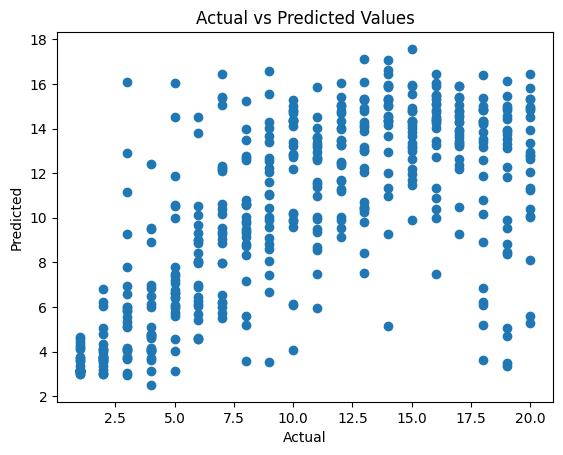

In [18]:
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted Values")
plt.show()



---


**21.Predicting race positions**

This part aims to predict Formula 1 drivers’ final positions for the 2026 season using machine learning. By training a regression model on historical racing data (before 2026), the system learns patterns between race-related features such as qualifying position, laps completed, and points, and the final race outcome. The goal is to generate a ranked prediction of driver performance for the upcoming season.

In [19]:
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

# 1. LOAD DATA
df = pd.read_excel("F1_dataset_2024-2026.xlsx")

# 2. FILTER DATA
train_data = df[df['Year'] < 2026].copy()
predict_data = df[df['Year'] == 2026].copy()

# 3. FEATURES & TARGET
features = ['Quali Position', 'Grid Position']
target = 'Final Position'

train_data['Quali Position'] = pd.to_numeric(train_data['Quali Position'], errors='coerce')
train_data['Grid Position'] = pd.to_numeric(train_data['Grid Position'], errors='coerce')
train_data['Quali Position'] = train_data['Quali Position'].fillna(train_data['Quali Position'].median())
train_data['Grid Position'] = train_data['Grid Position'].fillna(train_data['Grid Position'].median())

X = train_data[features]
y = pd.to_numeric(train_data[target], errors='coerce').fillna(0)

# 4. TRAIN / TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. TRAIN MODEL
model = Ridge(alpha=10, solver='auto')
model.fit(X_train, y_train)

# Check accuracy
y_pred_test = model.predict(X_test)
print("R2 Score:", round(r2_score(y_test, y_pred_test), 3))
print("MAE:", round(mean_absolute_error(y_test, y_pred_test), 2))

# 6. PREDICT 2026
predict_data['Quali Position'] = pd.to_numeric(predict_data['Quali Position'], errors='coerce')
predict_data['Grid Position'] = pd.to_numeric(predict_data['Grid Position'], errors='coerce')
predict_data['Quali Position'] = predict_data['Quali Position'].fillna(train_data['Quali Position'].median())
predict_data['Grid Position'] = predict_data['Grid Position'].fillna(train_data['Grid Position'].median())

X_2026 = predict_data[features]
predict_data['predicted_position_raw'] = model.predict(X_2026)

# 7. AVERAGE PER DRIVER
driver_avg = predict_data.groupby('Driver')['predicted_position_raw'].mean().reset_index()
driver_avg = driver_avg.sort_values('predicted_position_raw').reset_index(drop=True)
driver_avg['Predicted_Position'] = range(1, len(driver_avg) + 1)

# 8. ADD GROUP
def group_position(pos):
    if pos <= 3:    return "Top 3"
    elif pos <= 10: return "Top 10"
    else:           return "Others"

driver_avg['Group'] = driver_avg['Predicted_Position'].apply(group_position)

# 9. SAVE
final_output = driver_avg[['Driver', 'Predicted_Position', 'Group']]
final_output.to_excel("predictions_2026.xlsx", index=False)
joblib.dump(model, "regression_model.pkl")
joblib.dump(features, "regression_features.pkl")

print("\n✅ Done!")
print(final_output.to_string(index=False))

R2 Score: 0.54
MAE: 3.07

✅ Done!
           Driver  Predicted_Position  Group
   George Russell                   1  Top 3
   Kimi Antonelli                   2  Top 3
     Isack Hadjar                   3  Top 3
  Charles Leclerc                   4 Top 10
    Oscar Piastri                   5 Top 10
     Lando Norris                   6 Top 10
   Lewis Hamilton                   7 Top 10
      Liam Lawson                   8 Top 10
   Arvid Lindblad                   9 Top 10
Gabriel Bortoleto                  10 Top 10
  Nico Hulkenberg                  11 Others
   Oliver Bearman                  12 Others
     Esteban Ocon                  13 Others
     Pierre Gasly                  14 Others
  Alexander Albon                  15 Others
 Franco Colapinto                  16 Others
  Fernando Alonso                  17 Others
     Sergio Perez                  18 Others
  Valtteri Bottas                  19 Others
   Max Verstappen                  20 Others
     Carlos Sainz    



---


**Analysis**

The model does not directly “understand” racing outcomes but instead learns statistical relationships between performance indicators and final results. Ridge Regression was chosen because it stabilizes predictions when features are correlated (for example, qualifying position and race result trends often overlap).

However, since Formula 1 results depend on many unpredictable factors (weather, crashes, strategy, car upgrades), the model can only provide an approximate prediction rather than exact results. The ranking step improves by converting numerical predictions into a realistic leaderboard format.

In [20]:
import joblib

joblib.dump(best_model, "regression_model.pkl")
joblib.dump(list(important_features), "regression_features.pkl")

print("✅ regression_model.pkl and regression_features.pkl saved!")

✅ regression_model.pkl and regression_features.pkl saved!
